In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, log_loss, confusion_matrix, roc_curve
)
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 150, 'font.size': 10, 'axes.titlesize': 10.5})
sns.set_style("whitegrid")
SEED = 42
np.random.seed(SEED)

PATH = "/Users/ganjispandana/Downloads/MtechIITgn/sem3/ml/project/"  # Update if needed
CSV_PATH = os.path.join(PATH, "nifty50_2011-2026.csv")
assert os.path.exists(CSV_PATH), f"Expected canonical dataset '{CSV_PATH}' not found."

# 1. Load & standardize mixed date formats
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
df['Date'] = pd.to_datetime(df['Date'].str.strip(), format='mixed', dayfirst=True)
df = df.sort_values('Date').reset_index(drop=True)

dup_dates = df['Date'].duplicated().sum()
ohlc_valid = (
    (df['Low'] <= np.minimum(df['Open'], df['Close'])) &
    (df['High'] >= np.maximum(df['Open'], df['Close'])) &
    (df['Low'] <= df['High'])
)
weekend_rows = df[df['Date'].dt.dayofweek >= 5]

print(f"Total rows: {len(df)} | Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Duplicate dates: {dup_dates} | OHLC violations: {(~ohlc_valid).sum()} | Weekend/Special sessions: {len(weekend_rows)}")

df['Next_Open'] = df['Open'].shift(-1)
df['Next_Gap_Pct'] = (df['Next_Open'] - df['Close']) / df['Close']
df['Gap_Direction'] = (df['Next_Open'] > df['Close']).astype(float)
df = df.dropna(subset=['Next_Open']).reset_index(drop=True)
df['Gap_Direction'] = df['Gap_Direction'].astype(int)

Total rows: 3903 | Date range: 2011-01-03 to 2026-09-30
Duplicate dates: 0 | OHLC violations: 0 | Weekend/Special sessions: 18


In [21]:
def build_features(data):
    d = data.copy()
    for k in [0, 1, 2, 3, 5]:
        d[f'ret_lag_{k}'] = d['Close'].pct_change(1).shift(k)
    d['ret_5d_cum'] = d['Close'].pct_change(5)
    d['ret_10d_cum'] = d['Close'].pct_change(10)
    
    hl_range = (d['High'] - d['Low']).replace(0, np.nan)
    d['clv'] = (((d['Close'] - d['Low']) - (d['High'] - d['Close'])) / hl_range).fillna(0.0)
    d['clv_lag_1'] = d['clv'].shift(1)
    
    d['overnight_ret_t'] = (d['Open'] / d['Close'].shift(1)) - 1.0
    d['overnight_ret_lag1'] = d['overnight_ret_t'].shift(1)
    d['intraday_ret_t'] = (d['Close'] / d['Open']) - 1.0
    d['intraday_ret_lag1'] = d['intraday_ret_t'].shift(1)
    
    prev_close = d['Close'].shift(1)
    tr = np.maximum(
        d['High'] - d['Low'],
        np.maximum(np.abs(d['High'] - prev_close), np.abs(d['Low'] - prev_close))
    )
    d['atr_ratio_5_20'] = tr.rolling(5).mean() / tr.rolling(20).mean().replace(0, np.nan)
    d['vol_10d'] = d['ret_lag_0'].rolling(10).std()
    d['vol_20d'] = d['ret_lag_0'].rolling(20).std()
    
    up_day = (d['Close'] > d['Close'].shift(1)).astype(int)
    down_day = (d['Close'] < d['Close'].shift(1)).astype(int)
    d['streak'] = (
        up_day.groupby((up_day == 0).cumsum()).cumsum() -
        down_day.groupby((down_day == 0).cumsum()).cumsum()
    )
    ema_5 = d['Close'].ewm(span=5, adjust=False).mean()
    ema_20 = d['Close'].ewm(span=20, adjust=False).mean()
    d['dist_ema5'] = (d['Close'] - ema_5) / ema_5
    d['dist_ema20'] = (d['Close'] - ema_20) / ema_20
    
    dow = d['Date'].dt.dayofweek
    d['is_friday'] = (dow == 4).astype(int)
    d['is_monday'] = (dow == 0).astype(int)
    d['is_thursday'] = (dow == 3).astype(int)
    return d

df_feat = build_features(df).dropna().reset_index(drop=True)

# Full 22-Feature Set
full_cols = [
    'ret_lag_0', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_5', 'ret_5d_cum', 'ret_10d_cum',
    'clv', 'clv_lag_1', 'overnight_ret_t', 'overnight_ret_lag1',
    'intraday_ret_t', 'intraday_ret_lag1', 'atr_ratio_5_20',
    'vol_10d', 'vol_20d', 'streak', 'dist_ema5', 'dist_ema20',
    'is_friday', 'is_monday', 'is_thursday'
]


In [22]:
n = len(df_feat)
train_end, val_end = int(0.70 * n), int(0.85 * n)
train_df = df_feat.iloc[:train_end].copy()
val_df = df_feat.iloc[train_end:val_end].copy()
test_df = df_feat.iloc[val_end:].copy()

X_tr, y_tr = train_df[full_cols].values, train_df['Gap_Direction'].values
X_va, y_va = val_df[full_cols].values, val_df['Gap_Direction'].values
X_te, y_te = test_df[full_cols].values, test_df['Gap_Direction'].values

scaler = StandardScaler()
X_tr_sc = scaler.fit_transform(X_tr)
X_va_sc = scaler.transform(X_va)
X_te_sc = scaler.transform(X_te)

train_vol_thresh = train_df['vol_20d'].quantile(0.75)

def get_metrics(y_true, y_prob, thresh=0.5):
    y_pred = (y_prob >= thresh).astype(int)
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced_Acc': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_true, y_prob) if len(np.unique(y_prob)) > 1 else 0.5,
        'Log_Loss': log_loss(y_true, np.clip(y_prob, 1e-6, 1 - 1e-6))
    }

full_model_results = {}
all_test_probs = {}
all_val_probs = {}


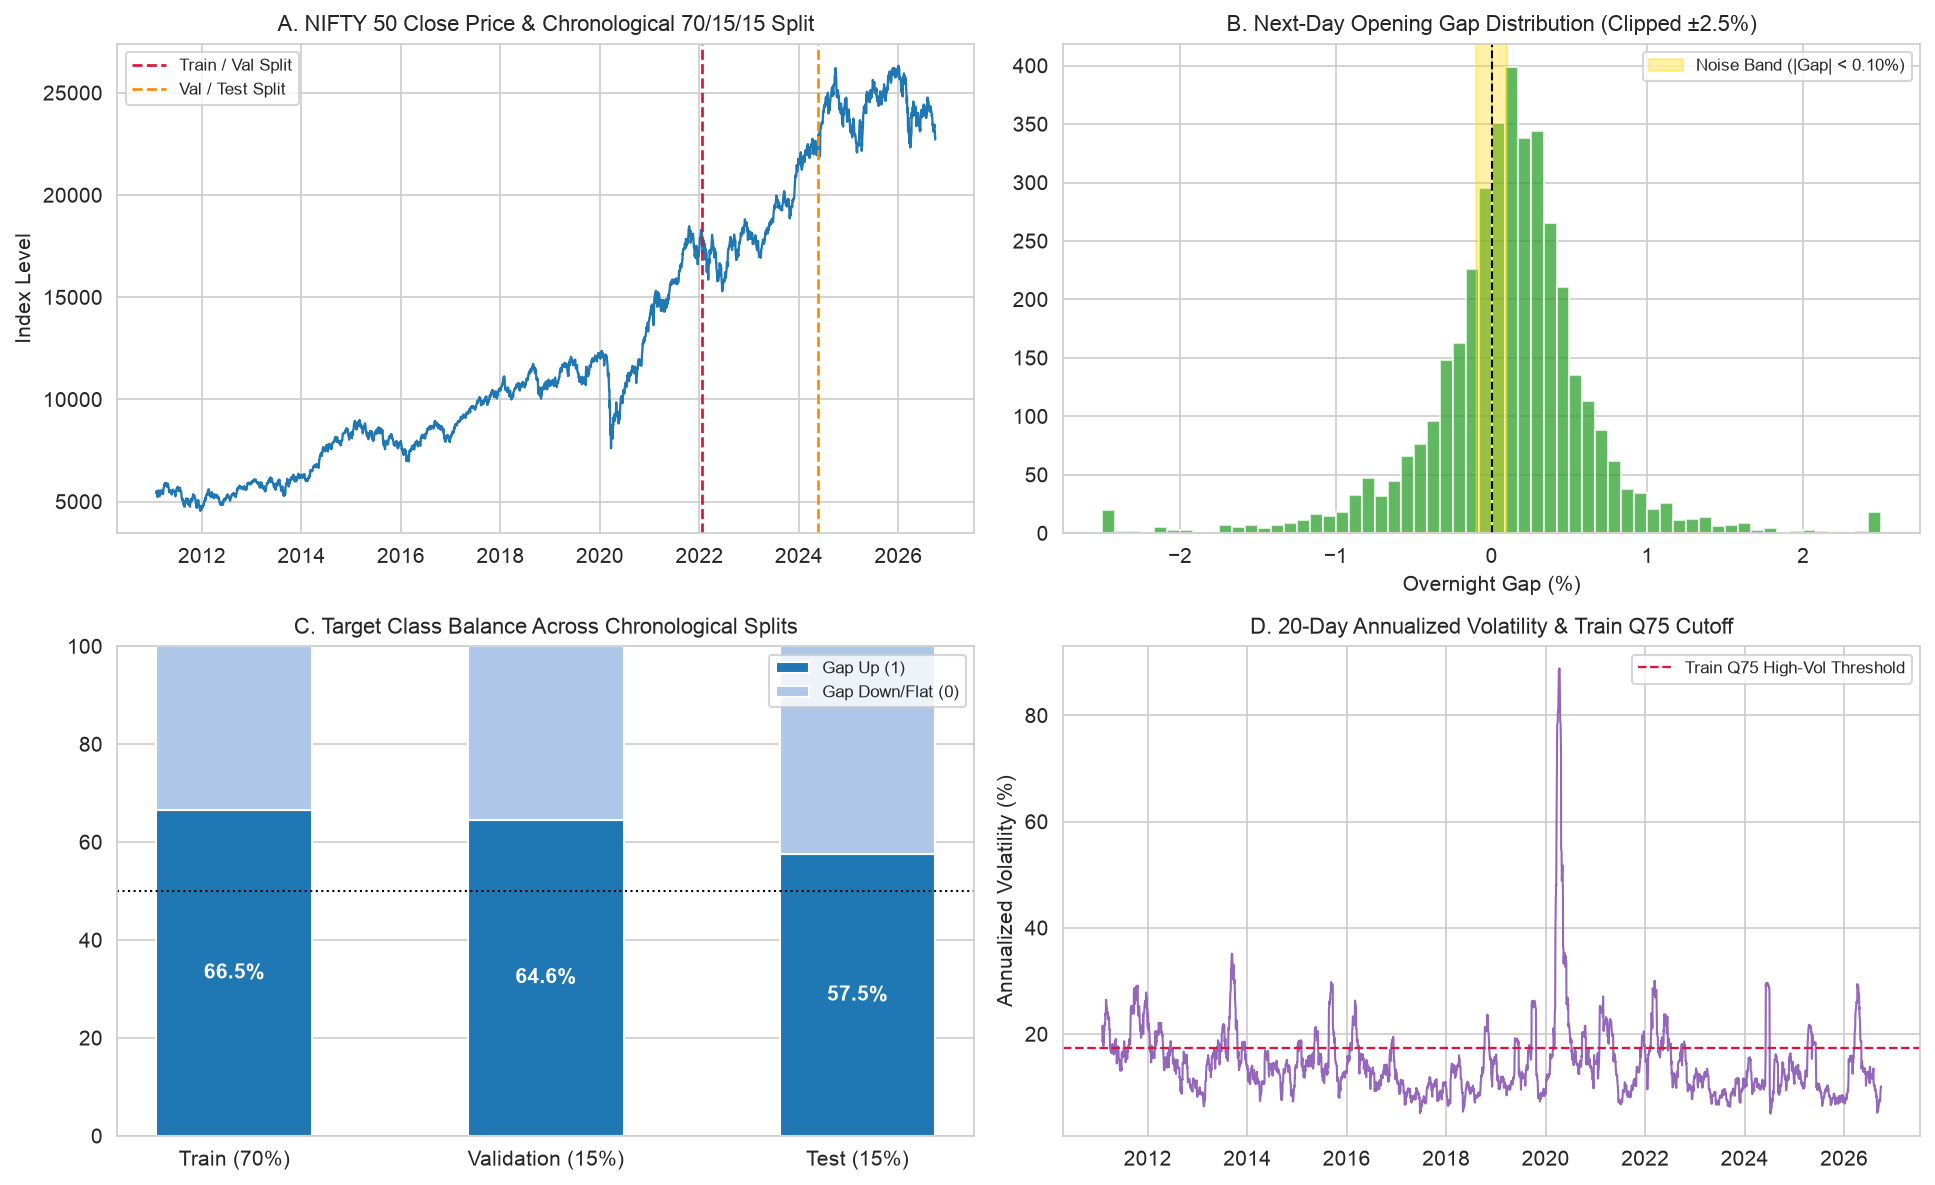

In [23]:

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(df_feat['Date'], df_feat['Close'], color='#1f77b4', lw=1.1)
axes[0, 0].axvline(train_df['Date'].max(), color='crimson', ls='--', lw=1.3, label='Train / Val Split')
axes[0, 0].axvline(val_df['Date'].max(), color='darkorange', ls='--', lw=1.3, label='Val / Test Split')
axes[0, 0].set_title('A. NIFTY 50 Close Price & Chronological 70/15/15 Split')
axes[0, 0].set_ylabel('Index Level')
axes[0, 0].legend(loc='upper left', fontsize=8)

gaps_pct = df_feat['Next_Gap_Pct'] * 100
axes[0, 1].hist(gaps_pct.clip(-2.5, 2.5), bins=60, color='#2ca02c', alpha=0.75, edgecolor='white')
axes[0, 1].axvline(0, color='black', ls='--', lw=1)
axes[0, 1].axvspan(-0.10, 0.10, color='gold', alpha=0.35, label='Noise Band (|Gap| < 0.10%)')
axes[0, 1].set_title('B. Next-Day Opening Gap Distribution (Clipped ±2.5%)')
axes[0, 1].set_xlabel('Overnight Gap (%)')
axes[0, 1].legend(fontsize=8)

split_names = ['Train (70%)', 'Validation (15%)', 'Test (15%)']
pos_rates = [train_df['Gap_Direction'].mean()*100, val_df['Gap_Direction'].mean()*100, test_df['Gap_Direction'].mean()*100]
neg_rates = [100 - p for p in pos_rates]
x = np.arange(len(split_names))
axes[1, 0].bar(x, pos_rates, width=0.5, label='Gap Up (1)', color='#1f77b4')
axes[1, 0].bar(x, neg_rates, width=0.5, bottom=pos_rates, label='Gap Down/Flat (0)', color='#aec7e8')
for i, p in enumerate(pos_rates):
    axes[1, 0].text(i, p/2, f"{p:.1f}%", ha='center', va='center', color='white', fontweight='bold')
axes[1, 0].axhline(50, color='black', ls=':', lw=1)
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(split_names)
axes[1, 0].set_ylim(0, 100)
axes[1, 0].set_title('C. Target Class Balance Across Chronological Splits')
axes[1, 0].legend(loc='upper right', fontsize=8)

ann_vol = df_feat['vol_20d'] * np.sqrt(252) * 100
axes[1, 1].plot(df_feat['Date'], ann_vol, color='#9467bd', lw=1.0)
axes[1, 1].axhline(train_vol_thresh * np.sqrt(252) * 100, color='crimson', ls='--', lw=1.1, label='Train Q75 High-Vol Threshold')
axes[1, 1].set_title('D. 20-Day Annualized Volatility & Train Q75 Cutoff')
axes[1, 1].set_ylabel('Annualized Volatility (%)')
axes[1, 1].legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.savefig('step2_eda_regimes.png', bbox_inches='tight')
plt.show()

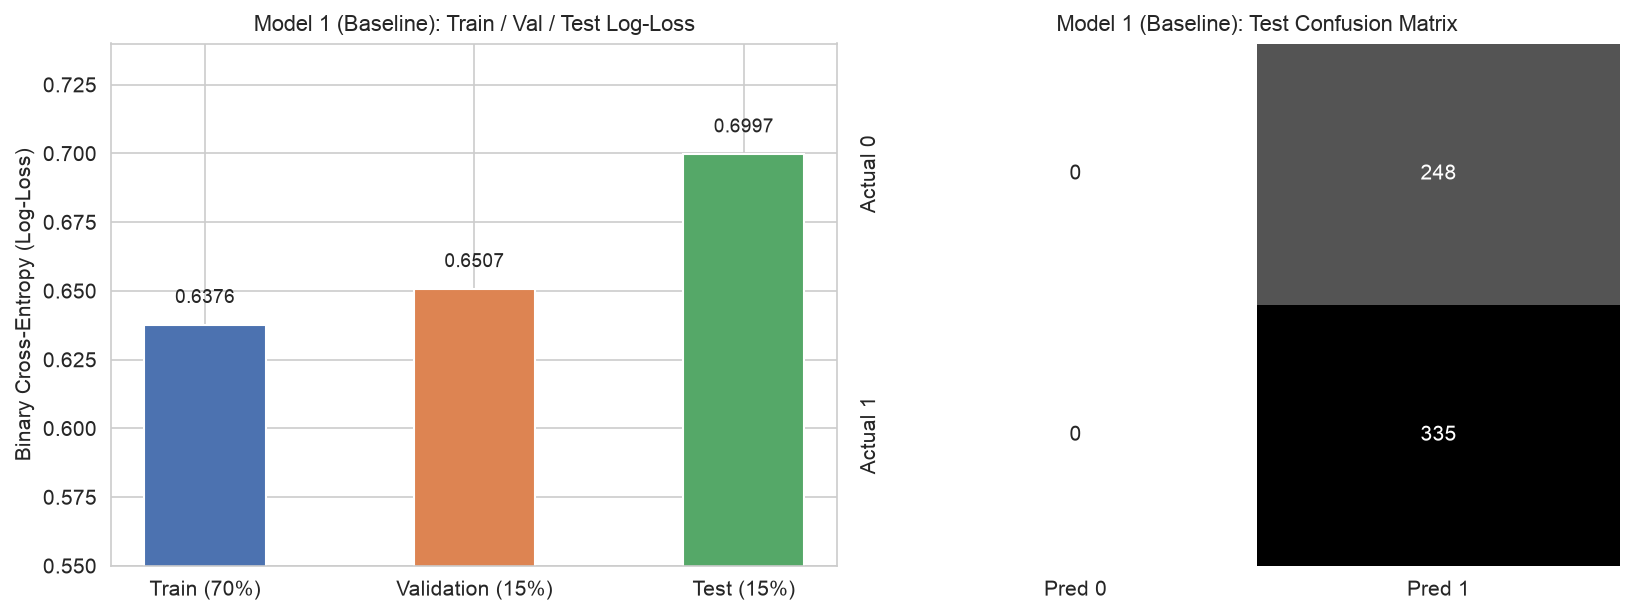

In [24]:
maj_class = int(np.round(y_tr.mean()))
maj_hard_te = np.full_like(y_te, fill_value=float(maj_class), dtype=float)
prior_prob = float(y_tr.mean())
prior_tr = np.full_like(y_tr, fill_value=prior_prob, dtype=float)
prior_va = np.full_like(y_va, fill_value=prior_prob, dtype=float)
prior_te = np.full_like(y_te, fill_value=prior_prob, dtype=float)

full_model_results['Majority Baseline'] = get_metrics(y_te, maj_hard_te)
all_test_probs['Majority Baseline'] = prior_te
all_val_probs['Majority Baseline'] = prior_va

base_losses = [log_loss(y_tr, prior_tr), log_loss(y_va, prior_va), log_loss(y_te, prior_te)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].bar(['Train (70%)', 'Validation (15%)', 'Test (15%)'], base_losses, color=['#4c72b0', '#dd8452', '#55a868'], width=0.45)
for i, v in enumerate(base_losses):
    axes[0].text(i, v + 0.008, f"{v:.4f}", ha='center', fontsize=9)
axes[0].set_ylim(0.55, 0.74)
axes[0].set_ylabel('Binary Cross-Entropy (Log-Loss)')
axes[0].set_title('Model 1 (Baseline): Train / Val / Test Log-Loss')

cm_maj = confusion_matrix(y_te, (maj_hard_te >= 0.5).astype(int))
sns.heatmap(cm_maj, annot=True, fmt='d', cmap='Greys', cbar=False, ax=axes[1],
            xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
axes[1].set_title('Model 1 (Baseline): Test Confusion Matrix')

plt.tight_layout()
plt.savefig('plot_model1_baseline.png', bbox_inches='tight')
plt.show()

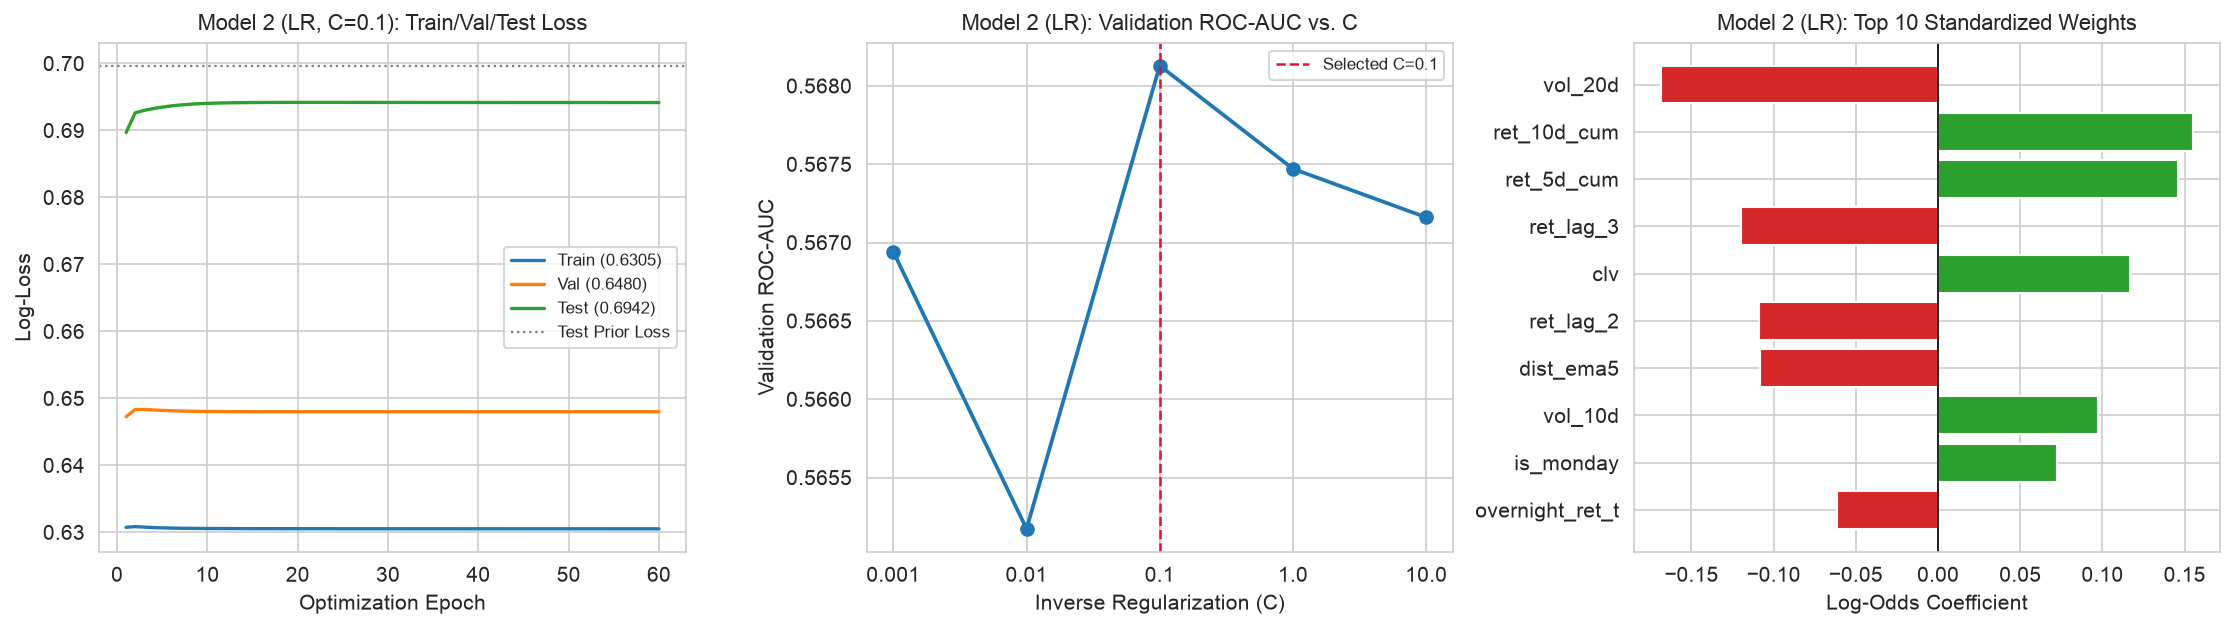

In [25]:
C_grid = [0.001, 0.01, 0.1, 1.0, 10.0]
val_aucs_lr = []
best_lr, best_auc_lr = None, -1
for C in C_grid:
    clf = LogisticRegression(C=C, max_iter=1000, random_state=SEED)
    clf.fit(X_tr_sc, y_tr)
    auc = roc_auc_score(y_va, clf.predict_proba(X_va_sc)[:, 1])
    val_aucs_lr.append(auc)
    if auc > best_auc_lr:
        best_auc_lr, best_lr = auc, clf

prob_te_lr = best_lr.predict_proba(X_te_sc)[:, 1]
prob_va_lr = best_lr.predict_proba(X_va_sc)[:, 1]
full_model_results['Logistic Regression'] = get_metrics(y_te, prob_te_lr)
all_test_probs['Logistic Regression'] = prob_te_lr
all_val_probs['Logistic Regression'] = prob_va_lr

alpha_l2 = 1.0 / (len(X_tr_sc) * best_lr.C)
sgd_lr = SGDClassifier(loss='log_loss', penalty='l2', alpha=alpha_l2, learning_rate='constant', eta0=0.005, random_state=SEED)
epochs_lr = 60
tr_loss_lr, va_loss_lr, te_loss_lr = [], [], []
for ep in range(epochs_lr):
    sgd_lr.partial_fit(X_tr_sc, y_tr, classes=[0, 1])
    tr_loss_lr.append(log_loss(y_tr, sgd_lr.predict_proba(X_tr_sc)[:, 1]))
    va_loss_lr.append(log_loss(y_va, sgd_lr.predict_proba(X_va_sc)[:, 1]))
    te_loss_lr.append(log_loss(y_te, sgd_lr.predict_proba(X_te_sc)[:, 1]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
ep_axis = np.arange(1, epochs_lr + 1)
axes[0].plot(ep_axis, tr_loss_lr, label=f'Train ({tr_loss_lr[-1]:.4f})', color='#1f77b4', lw=1.6)
axes[0].plot(ep_axis, va_loss_lr, label=f'Val ({va_loss_lr[-1]:.4f})', color='#ff7f0e', lw=1.6)
axes[0].plot(ep_axis, te_loss_lr, label=f'Test ({te_loss_lr[-1]:.4f})', color='#2ca02c', lw=1.6)
axes[0].axhline(base_losses[2], color='gray', ls=':', lw=1.1, label='Test Prior Loss')
axes[0].set_title(f'Model 2 (LR, C={best_lr.C}): Train/Val/Test Loss')
axes[0].set_xlabel('Optimization Epoch')
axes[0].set_ylabel('Log-Loss')
axes[0].legend(fontsize=8)

axes[1].plot([str(c) for c in C_grid], val_aucs_lr, marker='o', color='#1f77b4', lw=1.8)
axes[1].axvline(str(best_lr.C), color='crimson', ls='--', lw=1.2, label=f'Selected C={best_lr.C}')
axes[1].set_title('Model 2 (LR): Validation ROC-AUC vs. C')
axes[1].set_xlabel('Inverse Regularization (C)')
axes[1].set_ylabel('Validation ROC-AUC')
axes[1].legend(fontsize=8)

coefs = pd.Series(best_lr.coef_[0], index=full_cols)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=True).tail(10).index)
axes[2].barh(top_coefs.index, top_coefs.values, color=['#d62728' if v < 0 else '#2ca02c' for v in top_coefs.values])
axes[2].axvline(0, color='black', lw=0.8)
axes[2].set_title('Model 2 (LR): Top 10 Standardized Weights')
axes[2].set_xlabel('Log-Odds Coefficient')

plt.tight_layout()
plt.savefig('plot_model2_lr.png', bbox_inches='tight')
plt.show()

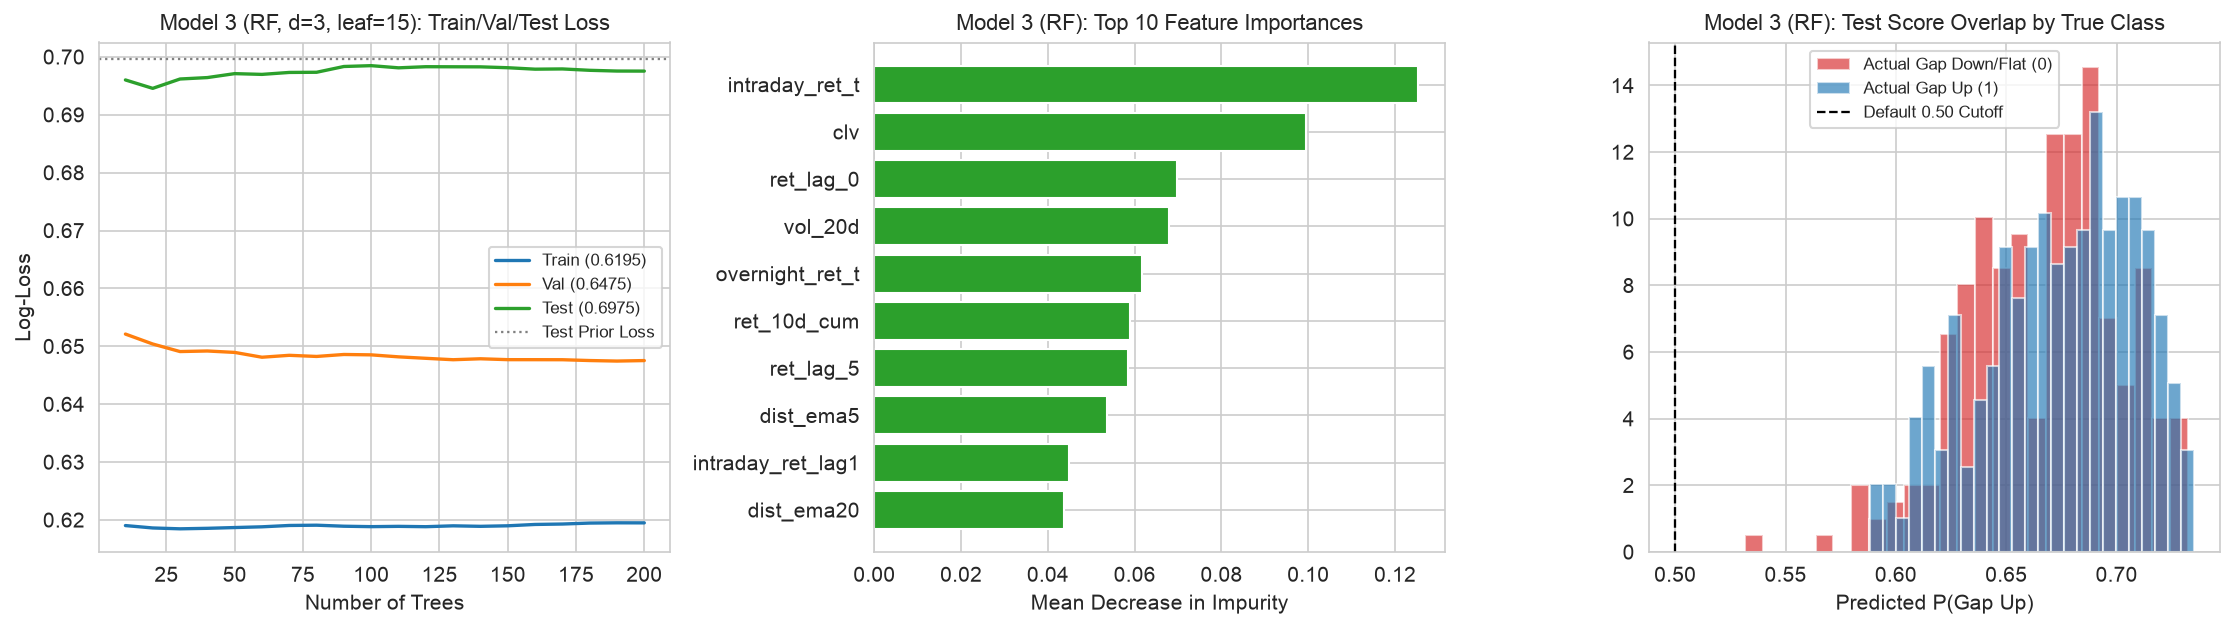

In [26]:
rf_grid = [(d, l) for d in [3, 5, 7] for l in [15, 30, 50]]
best_rf, best_auc_rf = None, -1
for max_d, min_leaf in rf_grid:
    clf = RandomForestClassifier(n_estimators=200, max_depth=max_d, min_samples_leaf=min_leaf, random_state=SEED, n_jobs=-1)
    clf.fit(X_tr, y_tr)
    auc = roc_auc_score(y_va, clf.predict_proba(X_va)[:, 1])
    if auc > best_auc_rf:
        best_auc_rf, best_rf = auc, clf

prob_te_rf = best_rf.predict_proba(X_te)[:, 1]
prob_va_rf = best_rf.predict_proba(X_va)[:, 1]
full_model_results['Random Forest'] = get_metrics(y_te, prob_te_rf)
all_test_probs['Random Forest'] = prob_te_rf
all_val_probs['Random Forest'] = prob_va_rf

tree_steps = np.arange(10, 210, 10)
tr_loss_rf, va_loss_rf, te_loss_rf = [], [], []
rf_warm = RandomForestClassifier(
    n_estimators=10, max_depth=best_rf.max_depth,
    min_samples_leaf=best_rf.min_samples_leaf, warm_start=True, random_state=SEED, n_jobs=-1
)
for n_t in tree_steps:
    rf_warm.n_estimators = n_t
    rf_warm.fit(X_tr, y_tr)
    tr_loss_rf.append(log_loss(y_tr, rf_warm.predict_proba(X_tr)[:, 1]))
    va_loss_rf.append(log_loss(y_va, rf_warm.predict_proba(X_va)[:, 1]))
    te_loss_rf.append(log_loss(y_te, rf_warm.predict_proba(X_te)[:, 1]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].plot(tree_steps, tr_loss_rf, label=f'Train ({tr_loss_rf[-1]:.4f})', color='#1f77b4', lw=1.6)
axes[0].plot(tree_steps, va_loss_rf, label=f'Val ({va_loss_rf[-1]:.4f})', color='#ff7f0e', lw=1.6)
axes[0].plot(tree_steps, te_loss_rf, label=f'Test ({te_loss_rf[-1]:.4f})', color='#2ca02c', lw=1.6)
axes[0].axhline(base_losses[2], color='gray', ls=':', lw=1.1, label='Test Prior Loss')
axes[0].set_title(f'Model 3 (RF, d={best_rf.max_depth}, leaf={best_rf.min_samples_leaf}): Train/Val/Test Loss')
axes[0].set_xlabel('Number of Trees')
axes[0].set_ylabel('Log-Loss')
axes[0].legend(fontsize=8)

rf_imp = pd.Series(best_rf.feature_importances_, index=full_cols).sort_values(ascending=True).tail(10)
axes[1].barh(rf_imp.index, rf_imp.values, color='#2ca02c')
axes[1].set_title('Model 3 (RF): Top 10 Feature Importances')
axes[1].set_xlabel('Mean Decrease in Impurity')

axes[2].hist(prob_te_rf[y_te == 0], bins=25, alpha=0.65, label='Actual Gap Down/Flat (0)', color='#d62728', density=True)
axes[2].hist(prob_te_rf[y_te == 1], bins=25, alpha=0.65, label='Actual Gap Up (1)', color='#1f77b4', density=True)
axes[2].axvline(0.50, color='black', ls='--', lw=1.1, label='Default 0.50 Cutoff')
axes[2].set_title('Model 3 (RF): Test Score Overlap by True Class')
axes[2].set_xlabel('Predicted P(Gap Up)')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('plot_model3_rf.png', bbox_inches='tight')
plt.show()

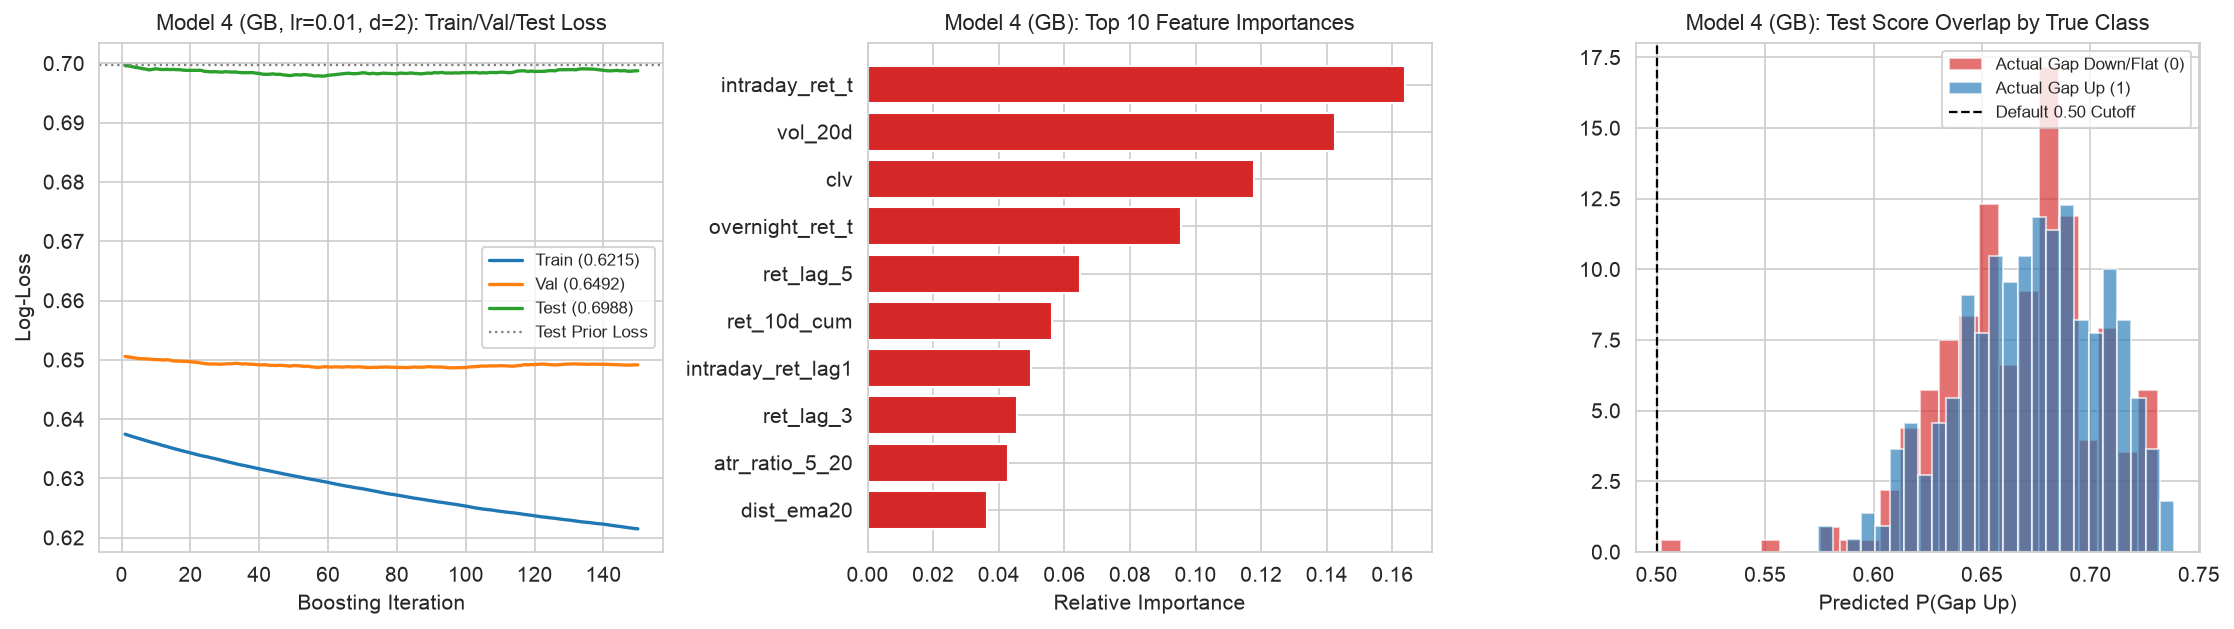

In [27]:
gb_grid = [(lr, d) for lr in [0.01, 0.03, 0.05] for d in [2, 3]]
best_gb, best_auc_gb = None, -1
for lr_rate, max_d in gb_grid:
    clf = GradientBoostingClassifier(
        n_estimators=150, learning_rate=lr_rate, max_depth=max_d,
        min_samples_leaf=25, subsample=0.8, random_state=SEED
    )
    clf.fit(X_tr, y_tr)
    auc = roc_auc_score(y_va, clf.predict_proba(X_va)[:, 1])
    if auc > best_auc_gb:
        best_auc_gb, best_gb = auc, clf

prob_te_gb = best_gb.predict_proba(X_te)[:, 1]
prob_va_gb = best_gb.predict_proba(X_va)[:, 1]
full_model_results['Gradient Boosting'] = get_metrics(y_te, prob_te_gb)
all_test_probs['Gradient Boosting'] = prob_te_gb
all_val_probs['Gradient Boosting'] = prob_va_gb

tr_loss_gb = [log_loss(y_tr, p[:, 1]) for p in best_gb.staged_predict_proba(X_tr)]
va_loss_gb = [log_loss(y_va, p[:, 1]) for p in best_gb.staged_predict_proba(X_va)]
te_loss_gb = [log_loss(y_te, p[:, 1]) for p in best_gb.staged_predict_proba(X_te)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
gb_iters = np.arange(1, len(tr_loss_gb) + 1)
axes[0].plot(gb_iters, tr_loss_gb, label=f'Train ({tr_loss_gb[-1]:.4f})', color='#1f77b4', lw=1.6)
axes[0].plot(gb_iters, va_loss_gb, label=f'Val ({va_loss_gb[-1]:.4f})', color='#ff7f0e', lw=1.6)
axes[0].plot(gb_iters, te_loss_gb, label=f'Test ({te_loss_gb[-1]:.4f})', color='#2ca02c', lw=1.6)
axes[0].axhline(base_losses[2], color='gray', ls=':', lw=1.1, label='Test Prior Loss')
axes[0].set_title(f'Model 4 (GB, lr={best_gb.learning_rate}, d={best_gb.max_depth}): Train/Val/Test Loss')
axes[0].set_xlabel('Boosting Iteration')
axes[0].set_ylabel('Log-Loss')
axes[0].legend(fontsize=8)

gb_imp = pd.Series(best_gb.feature_importances_, index=full_cols).sort_values(ascending=True).tail(10)
axes[1].barh(gb_imp.index, gb_imp.values, color='#d62728')
axes[1].set_title('Model 4 (GB): Top 10 Feature Importances')
axes[1].set_xlabel('Relative Importance')

axes[2].hist(prob_te_gb[y_te == 0], bins=25, alpha=0.65, label='Actual Gap Down/Flat (0)', color='#d62728', density=True)
axes[2].hist(prob_te_gb[y_te == 1], bins=25, alpha=0.65, label='Actual Gap Up (1)', color='#1f77b4', density=True)
axes[2].axvline(0.50, color='black', ls='--', lw=1.1, label='Default 0.50 Cutoff')
axes[2].set_title('Model 4 (GB): Test Score Overlap by True Class')
axes[2].set_xlabel('Predicted P(Gap Up)')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('plot_model4_gb.png', bbox_inches='tight')
plt.show()

In [28]:
# COMPARE ALL MODELS 
res_df = pd.DataFrame(full_model_results).T
print("\n TEST METRICS ACROSS ALL MODELS  ")
print(res_df.round(4).to_string())

def block_bootstrap_ci(y_true, y_prob, metric_fn, block_size=10, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    n_obs = len(y_true)
    n_blocks = int(np.ceil(n_obs / block_size))
    stats = []
    for _ in range(n_boot):
        starts = rng.randint(0, n_obs - block_size + 1, size=n_blocks)
        idx = np.concatenate([np.arange(s, s + block_size) for s in starts])[:n_obs]
        if len(np.unique(y_true[idx])) < 2:
            continue
        stats.append(metric_fn(y_true[idx], y_prob[idx]))
    return np.percentile(stats, [2.5, 97.5])

print("\n MOVING-BLOCK BOOTSTRAP 95% CIs ON TEST ROC-AUC  ")
for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting']:
    p = all_test_probs[name]
    ci_low, ci_high = block_bootstrap_ci(y_te, p, roc_auc_score)
    print(f"{name:22s}: ROC-AUC = {roc_auc_score(y_te, p):.4f} | 95% CI = [{ci_low:.4f}, {ci_high:.4f}]")





 TEST METRICS ACROSS ALL MODELS  
                     Accuracy  Balanced_Acc  Precision  Recall      F1  ROC_AUC  Log_Loss
Majority Baseline      0.5746        0.5000     0.5746   1.000  0.7298   0.5000    5.8769
Logistic Regression    0.5729        0.4985     0.5739   0.997  0.7285   0.5773    0.6931
Random Forest          0.5746        0.5000     0.5746   1.000  0.7298   0.5572    0.6975
Gradient Boosting      0.5746        0.5000     0.5746   1.000  0.7298   0.5462    0.6988

 MOVING-BLOCK BOOTSTRAP 95% CIs ON TEST ROC-AUC  
Logistic Regression   : ROC-AUC = 0.5773 | 95% CI = [0.5289, 0.6277]
Random Forest         : ROC-AUC = 0.5572 | 95% CI = [0.5063, 0.6092]
Gradient Boosting     : ROC-AUC = 0.5462 | 95% CI = [0.4890, 0.6003]


In [29]:
#  FEATURE ABLATION ON WINNING MODEL (LOGISTIC REGRESSION) 
feature_groups = {
    '1. Lagged Returns Only (Set A, 7 feats)': [
        'ret_lag_0', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_5', 'ret_5d_cum', 'ret_10d_cum'
    ],
    '2. + Intraday Microstructure (CLV & Gaps, 13 feats)': [
        'ret_lag_0', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_5', 'ret_5d_cum', 'ret_10d_cum',
        'clv', 'clv_lag_1', 'overnight_ret_t', 'overnight_ret_lag1', 'intraday_ret_t', 'intraday_ret_lag1'
    ],
    '3. + Volatility & Trend Context (19 feats)': [
        'ret_lag_0', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_5', 'ret_5d_cum', 'ret_10d_cum',
        'clv', 'clv_lag_1', 'overnight_ret_t', 'overnight_ret_lag1', 'intraday_ret_t', 'intraday_ret_lag1',
        'atr_ratio_5_20', 'vol_10d', 'vol_20d', 'streak', 'dist_ema5', 'dist_ema20'
    ],
    '4. Full Feature Set (+ Calendar, 22 feats)': full_cols
}

ablation_rows = []
for subset_name, cols in feature_groups.items():
    sc_sub = StandardScaler()
    Xtr_s = sc_sub.fit_transform(train_df[cols].values)
    Xva_s = sc_sub.transform(val_df[cols].values)
    Xte_s = sc_sub.transform(test_df[cols].values)
    
    best_sub_clf, best_sub_va = None, -1
    for C in C_grid:
        m = LogisticRegression(C=C, max_iter=1000, random_state=SEED).fit(Xtr_s, y_tr)
        va_auc = roc_auc_score(y_va, m.predict_proba(Xva_s)[:, 1])
        if va_auc > best_sub_va:
            best_sub_va, best_sub_clf = va_auc, m
            
    p_te = best_sub_clf.predict_proba(Xte_s)[:, 1]
    te_auc = roc_auc_score(y_te, p_te)
    te_ll = log_loss(y_te, p_te)
    ablation_rows.append({
        'Feature Subset': subset_name,
        'Num Feats': len(cols),
        'Best Val C': best_sub_clf.C,
        'Val ROC-AUC': best_sub_va,
        'Test ROC-AUC': te_auc,
        'Delta AUC vs Set A': te_auc - ablation_rows[0]['Test ROC-AUC'] if ablation_rows else 0.0,
        'Test Log-Loss': te_ll
    })

ablation_df = pd.DataFrame(ablation_rows)
print("\n PROGRESSIVE FEATURE ABLATION STUDY ")
print(ablation_df.round(4).to_string(index=False))

groups_dict = {
    'Lagged Returns (7)': ['ret_lag_0', 'ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_5', 'ret_5d_cum', 'ret_10d_cum'],
    'Intraday CLV & Gaps (6)': ['clv', 'clv_lag_1', 'overnight_ret_t', 'overnight_ret_lag1', 'intraday_ret_t', 'intraday_ret_lag1'],
    'Volatility & Trend (6)': ['atr_ratio_5_20', 'vol_10d', 'vol_20d', 'streak', 'dist_ema5', 'dist_ema20'],
    'Calendar Dummies (3)': ['is_friday', 'is_monday', 'is_thursday']
}
full_auc_ref = roc_auc_score(y_te, prob_te_lr)
logo_rows = []
for g_name, drop_cols in groups_dict.items():
    keep_cols = [c for c in full_cols if c not in drop_cols]
    sc_l = StandardScaler()
    Xtr_l = sc_l.fit_transform(train_df[keep_cols].values)
    Xva_l = sc_l.transform(val_df[keep_cols].values)
    Xte_l = sc_l.transform(test_df[keep_cols].values)
    best_l_clf, best_l_va = None, -1
    for C in C_grid:
        m = LogisticRegression(C=C, max_iter=1000, random_state=SEED).fit(Xtr_l, y_tr)
        va_auc = roc_auc_score(y_va, m.predict_proba(Xva_l)[:, 1])
        if va_auc > best_l_va:
            best_l_va, best_l_clf = va_auc, m
    drop_auc = roc_auc_score(y_te, best_l_clf.predict_proba(Xte_l)[:, 1])
    logo_rows.append({
        'Removed Feature Group': g_name,
        'Remaining Feats': len(keep_cols),
        'Test ROC-AUC': drop_auc,
        'AUC Drop vs Full': drop_auc - full_auc_ref
    })
logo_df = pd.DataFrame(logo_rows)
print("\n LEAVE-ONE-GROUP-OUT (LOGO) ABLATION FROM FULL SET ")
print(logo_df.round(4).to_string(index=False))


 PROGRESSIVE FEATURE ABLATION STUDY 
                                     Feature Subset  Num Feats  Best Val C  Val ROC-AUC  Test ROC-AUC  Delta AUC vs Set A  Test Log-Loss
            1. Lagged Returns Only (Set A, 7 feats)          7       0.010       0.5575        0.5531              0.0000         0.6979
2. + Intraday Microstructure (CLV & Gaps, 13 feats)         13       0.010       0.5658        0.5839              0.0308         0.6915
         3. + Volatility & Trend Context (19 feats)         19       0.001       0.5644        0.5810              0.0278         0.6948
         4. Full Feature Set (+ Calendar, 22 feats)         22       0.100       0.5681        0.5773              0.0242         0.6931

 LEAVE-ONE-GROUP-OUT (LOGO) ABLATION FROM FULL SET 
  Removed Feature Group  Remaining Feats  Test ROC-AUC  AUC Drop vs Full
     Lagged Returns (7)               15        0.5834            0.0061
Intraday CLV & Gaps (6)               16        0.5490           -0.0283
 Vola

In [30]:
#  DEPLOYMENT-RISK AUDIT & REPRESENTATIVE ERROR INSPECTION ---
thresholds = np.linspace(0.50, 0.72, 100)
val_bal_accs = [balanced_accuracy_score(y_va, (prob_va_lr >= t).astype(int)) for t in thresholds]
opt_thresh = thresholds[np.argmax(val_bal_accs)]

is_high_vol = test_df['vol_20d'].values >= train_vol_thresh
is_decisive_gap = test_df['Next_Gap_Pct'].abs().values >= 0.0010
mid_te = len(test_df) // 2

sub_masks = {
    'All Test Sessions': np.ones(len(test_df), dtype=bool),
    'Low/Normal Vol (Train <Q75)': ~is_high_vol,
    'High Vol (Train >=Q75)': is_high_vol,
    'Noise Gaps (|Gap| < 0.10%)': ~is_decisive_gap,
    'Decisive Gaps (|Gap| >= 0.10%)': is_decisive_gap,
    'Test H1 (2024-05 to 2025-07)': np.arange(len(test_df)) < mid_te,
    'Test H2 (2025-07 to 2026-09)': np.arange(len(test_df)) >= mid_te,
}

audit_records = []
for slice_name, mask in sub_masks.items():
    ys, ps = y_te[mask], prob_te_lr[mask]
    preds_opt = (ps >= opt_thresh).astype(int)
    tn, fp, fn, tp = confusion_matrix(ys, preds_opt, labels=[0, 1]).ravel()
    audit_records.append({
        'Audit Slice': slice_name,
        'N': int(mask.sum()),
        'Pos Rate': ys.mean(),
        'ROC-AUC': roc_auc_score(ys, ps),
        'Bal Acc (@opt)': balanced_accuracy_score(ys, preds_opt),
        'FPR (@opt)': fp / (fp + tn),
        'FNR (@opt)': fn / (fn + tp)
    })
audit_df = pd.DataFrame(audit_records)
print(f"\n=== STEP 7C: DEPLOYMENT-RISK AUDIT TABLE (LR Full Set, Val-Tuned Thresh = {opt_thresh:.3f}) ===")
print(audit_df.round(4).to_string(index=False))

test_audit = test_df[['Date', 'Close', 'Next_Open', 'Next_Gap_Pct', 'Gap_Direction', 'clv', 'vol_20d']].copy()
test_audit['Pred_Prob'] = prob_te_lr
test_audit['Abs_Error'] = np.abs(test_audit['Gap_Direction'] - test_audit['Pred_Prob'])
print("\n TOP 5 REPRESENTATIVE HIGH-CONFIDENCE ERRORS ")
print(test_audit.sort_values('Abs_Error', ascending=False).head(5).to_string(index=False))




=== STEP 7C: DEPLOYMENT-RISK AUDIT TABLE (LR Full Set, Val-Tuned Thresh = 0.660) ===
                   Audit Slice   N  Pos Rate  ROC-AUC  Bal Acc (@opt)  FPR (@opt)  FNR (@opt)
             All Test Sessions 583    0.5746   0.5773          0.5610      0.4960      0.3821
   Low/Normal Vol (Train <Q75) 492    0.5589   0.5872          0.5674      0.5161      0.3491
        High Vol (Train >=Q75)  91    0.6593   0.5790          0.5559      0.3548      0.5333
    Noise Gaps (|Gap| < 0.10%) 142    0.5282   0.5280          0.5015      0.5970      0.4000
Decisive Gaps (|Gap| >= 0.10%) 441    0.5896   0.5970          0.5823      0.4586      0.3769
  Test H1 (2024-05 to 2025-07) 291    0.6426   0.6044          0.5890      0.4423      0.3797
  Test H2 (2025-07 to 2026-09) 292    0.5068   0.5562          0.5401      0.5347      0.3851

 TOP 5 REPRESENTATIVE HIGH-CONFIDENCE ERRORS 
      Date    Close  Next_Open  Next_Gap_Pct  Gap_Direction      clv  vol_20d  Pred_Prob  Abs_Error
2026-02-04 2577

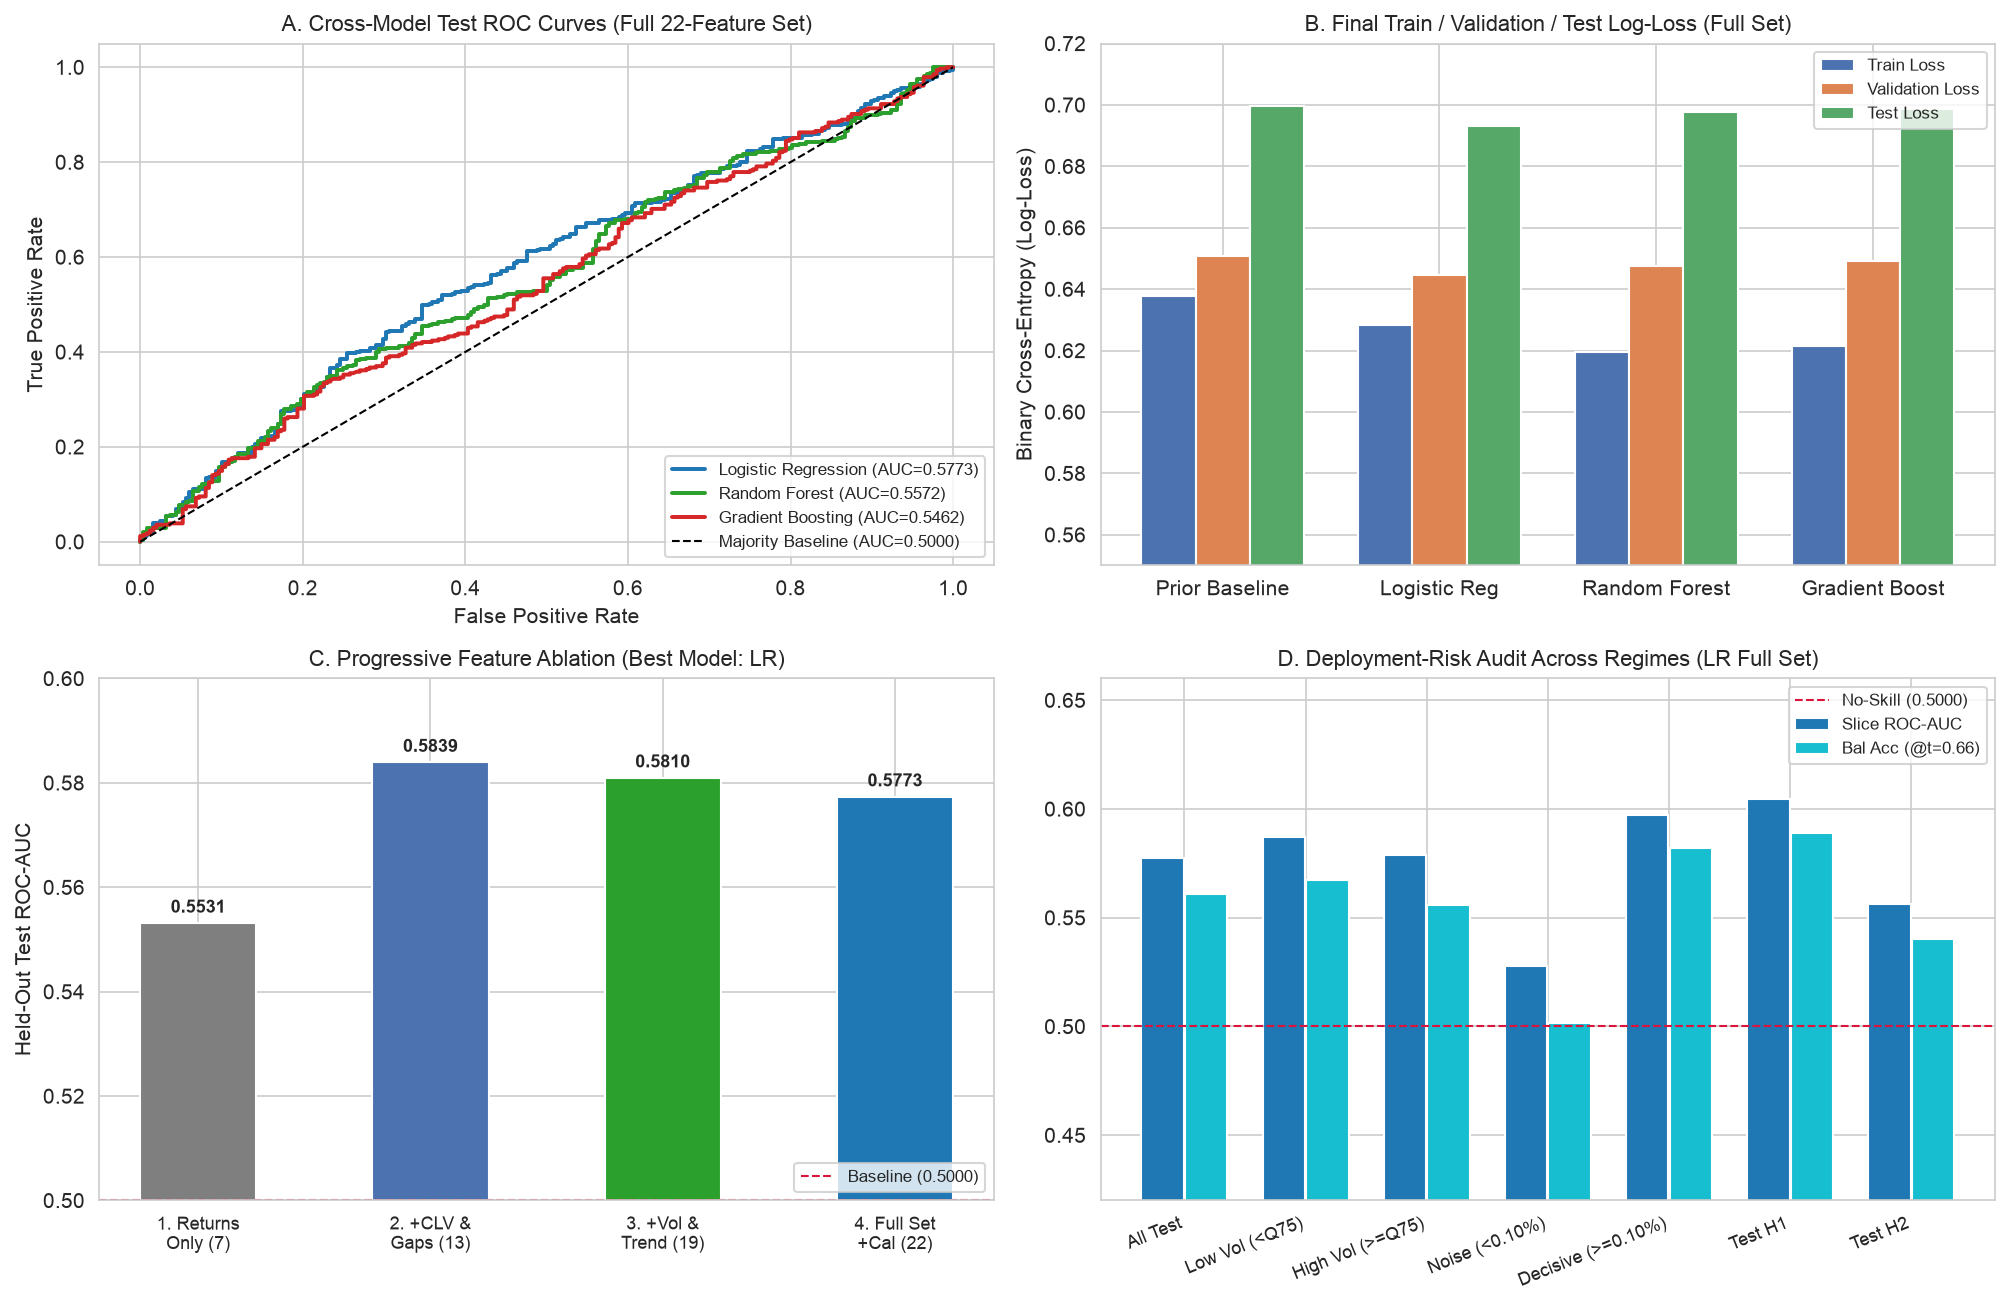

In [31]:
#  Summary Plot 
fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.8))

for name, color in [('Logistic Regression', '#1f77b4'), ('Random Forest', '#2ca02c'), ('Gradient Boosting', '#d62728')]:
    fpr, tpr, _ = roc_curve(y_te, all_test_probs[name])
    auc_s = roc_auc_score(y_te, all_test_probs[name])
    axes[0, 0].plot(fpr, tpr, label=f"{name} (AUC={auc_s:.4f})", lw=1.9, color=color)
axes[0, 0].plot([0, 1], [0, 1], 'k--', lw=1, label='Majority Baseline (AUC=0.5000)')
axes[0, 0].set_title('A. Cross-Model Test ROC Curves (Full 22-Feature Set)')
axes[0, 0].set_xlabel('False Positive Rate')
axes[0, 0].set_ylabel('True Positive Rate')
axes[0, 0].legend(loc='lower right', fontsize=8)

model_labels = ['Prior Baseline', 'Logistic Reg', 'Random Forest', 'Gradient Boost']
final_tr_losses = [base_losses[0], log_loss(y_tr, best_lr.predict_proba(X_tr_sc)[:, 1]), tr_loss_rf[-1], tr_loss_gb[-1]]
final_va_losses = [base_losses[1], log_loss(y_va, prob_va_lr), va_loss_rf[-1], va_loss_gb[-1]]
final_te_losses = [base_losses[2], log_loss(y_te, prob_te_lr), te_loss_rf[-1], te_loss_gb[-1]]

x = np.arange(len(model_labels))
w = 0.25
axes[0, 1].bar(x - w, final_tr_losses, width=w, label='Train Loss', color='#4c72b0')
axes[0, 1].bar(x, final_va_losses, width=w, label='Validation Loss', color='#dd8452')
axes[0, 1].bar(x + w, final_te_losses, width=w, label='Test Loss', color='#55a868')
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels(model_labels)
axes[0, 1].set_ylim(0.55, 0.72)
axes[0, 1].set_ylabel('Binary Cross-Entropy (Log-Loss)')
axes[0, 1].set_title('B. Final Train / Validation / Test Log-Loss (Full Set)')
axes[0, 1].legend(fontsize=8)

prog_labels = ['1. Returns\nOnly (7)', '2. +CLV &\nGaps (13)', '3. +Vol &\nTrend (19)', '4. Full Set\n+Cal (22)']
x_p = np.arange(len(prog_labels))
bars = axes[1, 0].bar(x_p, ablation_df['Test ROC-AUC'], width=0.5, color=['#7f7f7f', '#4c72b0', '#2ca02c', '#1f77b4'])
axes[1, 0].axhline(0.50, color='crimson', ls='--', lw=1, label='Baseline (0.5000)')
for bar in bars:
    h = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, h + 0.002, f"{h:.4f}", ha='center', fontsize=8.5, fontweight='bold')
axes[1, 0].set_xticks(x_p)
axes[1, 0].set_xticklabels(prog_labels, fontsize=8.5)
axes[1, 0].set_ylim(0.50, 0.60)
axes[1, 0].set_ylabel('Held-Out Test ROC-AUC')
axes[1, 0].set_title('C. Progressive Feature Ablation (Best Model: LR)')
axes[1, 0].legend(loc='lower right', fontsize=8)

short_labels = ['All Test', 'Low Vol (<Q75)', 'High Vol (>=Q75)', 'Noise (<0.10%)', 'Decisive (>=0.10%)', 'Test H1', 'Test H2']
x_s = np.arange(len(short_labels))
axes[1, 1].bar(x_s - 0.18, audit_df['ROC-AUC'], width=0.35, label='Slice ROC-AUC', color='#1f77b4')
axes[1, 1].bar(x_s + 0.18, audit_df['Bal Acc (@opt)'], width=0.35, label=f'Bal Acc (@t={opt_thresh:.2f})', color='#17becf')
axes[1, 1].axhline(0.50, color='crimson', ls='--', lw=1, label='No-Skill (0.5000)')
axes[1, 1].set_xticks(x_s)
axes[1, 1].set_xticklabels(short_labels, rotation=22, ha='right', fontsize=8.5)
axes[1, 1].set_ylim(0.42, 0.66)
axes[1, 1].set_title('D. Deployment-Risk Audit Across Regimes (LR Full Set)')
axes[1, 1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('step7_final_comparison.png', bbox_inches='tight')
plt.show()